# EDA complementario: precio por pie cuadrado
Complementa `src/eda.py`. El precio total mezcla dos efectos: el **tamaño** del apartamento y el **valor de la ubicación o del edificio**. Al dividir por el tamaño (`PricePerSqf`) se separan, y se puede ver cuánto de las diferencias por estación de metro y tipo de pasillo se debe solo a que los apartamentos son más grandes.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
sns.set_theme(style="whitegrid")
FIG = Path("../reports/figures"); FIG.mkdir(parents=True, exist_ok=True)
df = pd.read_csv("../data/raw/train_real_state.csv").drop_duplicates()
df["PricePerSqf"] = df.SalePrice / df["Size.sqf."]
df.shape

(3932, 31)

## 1. Estación de metro: precio total vs. precio por sqf

In [2]:
est = (df.groupby("SubwayStation")
         .agg(n=("SalePrice","size"), precio_med=("SalePrice","median"),
              tamano_med=("Size.sqf.","median"), psqf_med=("PricePerSqf","median"))
         .sort_values("psqf_med", ascending=False).round(0))
est

,n,precio_med,tamano_med,psqf_med
SubwayStation,,,,
Banwoldang,504,326548.0,1394.0,257.0
no_subway_nearby,261,207079.0,910.0,253.0
Kyungbuk_uni_hospital,1072,247787.0,910.0,248.0
Sin-nam,457,247787.0,914.0,233.0
Bangoge,460,175221.0,743.0,217.0
Myung-duk,1043,154867.0,843.0,182.0
Daegu,60,93584.0,587.0,159.0
Chil-sung-market,75,85840.0,644.0,135.0


In [3]:
r_precio = est.precio_med.max() / est.precio_med.min()
r_psqf = est.psqf_med.max() / est.psqf_med.min()
print(f"Brecha entre la estación más cara y la más barata: precio total {r_precio:.1f}x, precio por sqf {r_psqf:.1f}x")

Brecha entre la estación más cara y la más barata: precio total 3.8x, precio por sqf 1.9x


## 2. Tiempo al metro (a tamaño similar)

In [4]:
t_ord = ["0-5min","5min~10min","10min~15min","15min~20min","no_bus_stop_nearby"]
tt = (df.groupby("TimeToSubway")
        .agg(n=("SalePrice","size"), precio_med=("SalePrice","median"),
             tamano_med=("Size.sqf.","median"), psqf_med=("PricePerSqf","median"))
        .reindex(t_ord).round(0))
tt

,n,precio_med,tamano_med,psqf_med
TimeToSubway,,,,
0-5min,1830,283185.0,914.0,258.0
5min~10min,724,167920.0,743.0,230.0
10min~15min,566,163716.0,910.0,181.0
15min~20min,658,138053.0,907.0,148.0
no_bus_stop_nearby,154,203646.0,910.0,219.0


## 3. Tipo de pasillo: ¿efecto propio o proxy de tamaño y antigüedad?

In [5]:
hw = (df.groupby("HallwayType")
        .agg(precio_med=("SalePrice","median"), tamano_med=("Size.sqf.","median"),
             psqf_med=("PricePerSqf","median"), anio_constr_med=("YearBuilt","median"))
        .round(0))
hw

,precio_med,tamano_med,psqf_med,anio_constr_med
HallwayType,,,,
corridor,78097.0,576.0,167.0,1992.0
mixed,159292.0,743.0,185.0,1993.0
terraced,265486.0,914.0,252.0,2007.0


## 4. Figura para el reporte

/tmp/ipykernel_308/3728876083.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax[1].set_xticklabels(["0-5","5-10","10-15","15-20","sin metro"])


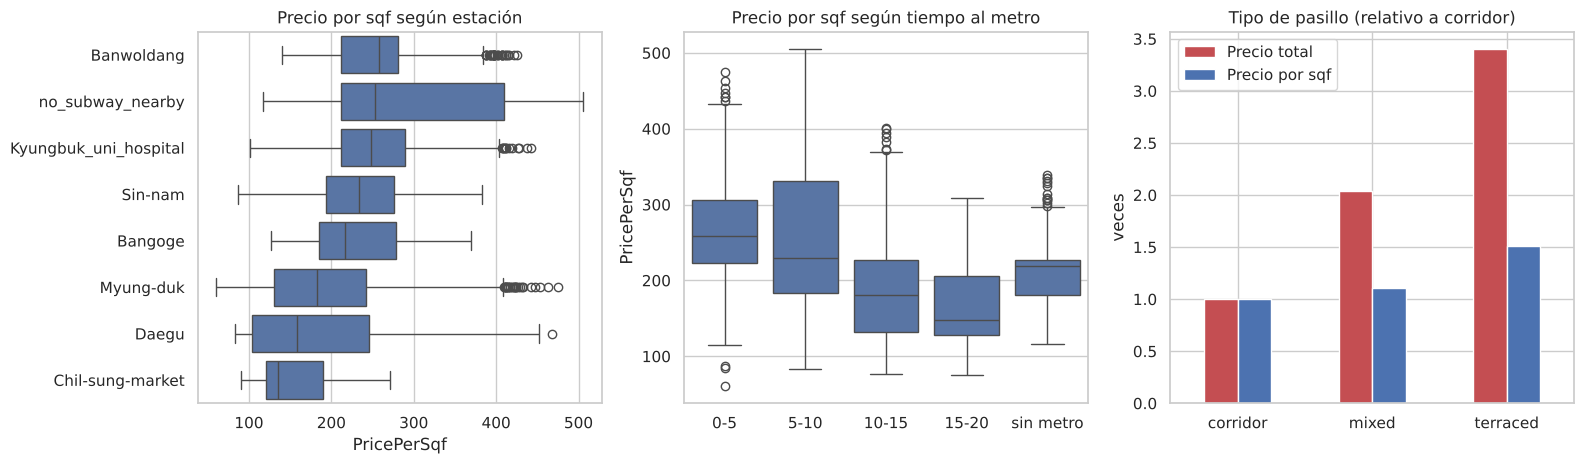

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
orden = est.index
sns.boxplot(data=df, y="SubwayStation", x="PricePerSqf", order=orden, ax=ax[0], color="#4C72B0")
ax[0].set_title("Precio por sqf según estación"); ax[0].set_ylabel("")
sns.boxplot(data=df, x="TimeToSubway", y="PricePerSqf", order=t_ord, ax=ax[1], color="#4C72B0")
ax[1].set_title("Precio por sqf según tiempo al metro"); ax[1].set_xlabel("")
ax[1].set_xticklabels(["0-5","5-10","10-15","15-20","sin metro"])
h = hw[["precio_med","psqf_med"]].div(hw[["precio_med","psqf_med"]].min()).reindex(["corridor","mixed","terraced"])
h.columns = ["Precio total", "Precio por sqf"]
h.plot.bar(ax=ax[2], rot=0, color=["#C44E52","#4C72B0"])
ax[2].set_title("Tipo de pasillo (relativo a corridor)"); ax[2].set_xlabel(""); ax[2].set_ylabel("veces")
plt.tight_layout(); plt.savefig(FIG/"eda2_precio_por_sqf.png", dpi=150); plt.show()

## 5. Hallazgos
1. **Parte de la diferencia entre estaciones es tamaño.** La brecha entre la estación más cara (Banwoldang) y la más barata (Chil-sung-market) es de 3,8 veces en precio total, pero de 1,9 veces en precio por sqf: en Banwoldang los apartamentos son mucho más grandes (mediana 1.394 sqf frente a ≈910 en las demás).
2. **El acceso al metro sí tiene un efecto claro.** Con tamaños medianos casi iguales (≈910 sqf), el precio por sqf baja de 258 (0–5 min) a 181 (10–15 min) y 148 (15–20 min).
3. **El tipo de pasillo es en buena parte un proxy.** Los apartamentos *corridor* son pequeños (576 sqf) y antiguos (1992); *terraced* son grandes (914 sqf) y nuevos (2007). La brecha baja de 3,4 veces en precio total a 1,5 veces en precio por sqf. Su alta importancia en el Random Forest base no debe leerse como efecto propio del pasillo.

**Implicaciones:** en el tablero, comparar zonas por precio por sqf y no por precio total; en el modelo, `TimeToSubway` como ordinal y revisar la importancia de variables con métodos que consideren la correlación entre ellas (por ejemplo, importancia por permutación agrupada o SHAP).